# DSA4213 Part III — Frozen LSTM representations for Yelp sentiment

**Research question:** How does the input-embedding setting used during LSTM language-model training affect frozen representations for downstream Yelp review sentiment classification?

Compare **random trainable**, **own CBOW frozen**, and **public GloVe frozen** embedding settings from Part II. 

**Dataset scope:** Yelp Review Polarity contains reviews of multiple business types, not only restaurants. The requested filename is retained for continuity; the experiment is business-review sentiment classification.

**Default experiment:** 8,000 train / 1,000 validation / 1,000 test; balanced binary labels; first 256 lexical tokens per review; non-overlapping chunks at the original LM block length; token-weighted mean pooling; `C = [0.01, 0.1, 1, 10]`; validation macro-F1 selection; threshold 0.5.

**Before running:** finish notebooks 06, 07 and 08. Their run folders are inputs, never modified here. Use **Runtime → Change runtime type → T4 GPU** if available. CPU also works. Run cells top-to-bottom. Defaults reuse valid cached work and compute missing work. On a later run, set both `EXTRACTION_MODE` and `CLASSIFIER_MODE` to `'reuse_only'` to prohibit recomputation.



## 1. Dependencies, imports, and Google Drive Mount

In [1]:
%pip -q install "datasets>=3,<5" "huggingface_hub>=0.27,<2" "scikit-learn>=1.5,<2" "pandas>=2,<3" "matplotlib>=3.8,<4" "joblib>=1.4,<2" "threadpoolctl>=3,<4" tqdm

In [2]:
import os
os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG', ':4096:8')
import gc, sys, json, math, time, random, hashlib, platform, subprocess, warnings, re
from pathlib import Path
from datetime import datetime, timezone
import importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from datasets import load_dataset
from huggingface_hub import HfApi
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from sklearn.exceptions import ConvergenceWarning
from sklearn.decomposition import PCA
from threadpoolctl import threadpool_limits
import joblib
from tqdm.auto import tqdm
from IPython.display import display, HTML, Markdown
from html import escape

try:
    from google.colab import drive
except ImportError:
    print('Outside Colab: set PROJECT_ROOT to your local copy in Section 2.')
else:
    drive.mount('/content/drive')

Mounted at /content/drive


## 2. Editable controls and experiment contract

In [3]:
PROJECT_ROOT = Path('/content/drive/MyDrive/DSA4213_Assignment1')
RUN_DIRS = {
    'random_trainable': PROJECT_ROOT/'runs/II_lstm_random_reuse_s42_v1',
    'cbow_frozen': PROJECT_ROOT/'runs/II_lstm_cbow_frozen_s42_v1',
    'glove_frozen': PROJECT_ROOT/'runs/II_lstm_glove_frozen_s42_v1',
}
OUTPUT_ROOT = PROJECT_ROOT/'partIII/yelp_polarity'
EXTRACTION_MODE = 'auto'      # 'auto' or 'reuse_only'
CLASSIFIER_MODE = 'auto'      # 'auto' or 'reuse_only'
DEVICE_REQUEST = 'auto'      # 'auto', 'cpu', or 'cuda'
SEED = 42
SAMPLE_COUNTS = {'train': 8000, 'validation': 1000, 'test': 1000}
MAX_REVIEW_TOKENS = 256       # Lexical tokenizer tokens, before BOS; fixed before test
EXTRACTION_BATCH_SIZE = 128  # Number of chunks, not reviews; reduce if GPU memory is low
CPU_THREADS = 2
C_GRID = [0.01, 0.1, 1.0, 10.0]
LR_MAX_ITER = 5000
LR_TOL = 1e-5
RUN_PCA = False              # Optional training-fitted PCA, descriptive only
EXAMPLES_PER_CATEGORY = 2
DATASET_ID = 'fancyzhx/yelp_polarity'
DATASET_REVISION = None      # None: resolve once and save; or supply a commit SHA
PIPELINE_VERSION = 'partIII_yelp_v1'
# Optional replacement for automatic Part II metrics loading. Leave both empty normally.
LM_RESULTS_CSV = None        # CSV columns: variant,test_ce,test_ppl,checkpoint_sha256
MANUAL_LM_RESULTS = []       # Same keys per dictionary; include exact checkpoint hash printed below

VARIANTS = list(RUN_DIRS)
DISPLAY_NAMES = {'random_trainable':'Random trainable', 'cbow_frozen':'CBOW frozen', 'glove_frozen':'GloVe frozen'}
COLORS = {'random_trainable':'#466C9B', 'cbow_frozen':'#C18B30', 'glove_frozen':'#8B619E'}
LABEL_NAMES = ['Negative', 'Positive']
assert EXTRACTION_MODE in {'auto','reuse_only'} and CLASSIFIER_MODE in {'auto','reuse_only'}
assert DEVICE_REQUEST in {'auto','cpu','cuda'}
assert MAX_REVIEW_TOKENS > 0 and EXTRACTION_BATCH_SIZE > 0
assert all(isinstance(n,int) and n>0 and n%2==0 for n in SAMPLE_COUNTS.values()), 'Use positive even split sizes for equal class quotas.'
assert C_GRID and len(set(C_GRID)) == len(C_GRID) and all(c>0 for c in C_GRID)
if DEVICE_REQUEST == 'cuda' and not torch.cuda.is_available():
    raise RuntimeError('CUDA requested but unavailable. Select a Colab GPU or DEVICE_REQUEST="cpu".')
DEVICE = torch.device(('cuda' if torch.cuda.is_available() else 'cpu') if DEVICE_REQUEST=='auto' else DEVICE_REQUEST)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
torch.set_num_threads(CPU_THREADS)
torch.backends.cudnn.benchmark=False; torch.backends.cudnn.deterministic=True
if torch.cuda.is_available():
    torch.backends.cuda.matmul.allow_tf32=False; torch.backends.cudnn.allow_tf32=False
torch.use_deterministic_algorithms(True, warn_only=True)
plt.rcParams.update({'figure.dpi':110, 'savefig.dpi':300, 'font.size':11,
                     'axes.spines.top':False, 'axes.spines.right':False})
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
print('Extraction device:', DEVICE)

Extraction device: cuda


In [4]:
def read_json(path):
    return json.loads(Path(path).read_text(encoding='utf-8'))

def sha256(path):
    h=hashlib.sha256()
    with Path(path).open('rb') as f:
        for chunk in iter(lambda:f.read(1024*1024), b''): h.update(chunk)
    return h.hexdigest()

def object_hash(obj):
    return hashlib.sha256(json.dumps(obj, sort_keys=True, ensure_ascii=False, allow_nan=False).encode()).hexdigest()

def write_json(path, obj):
    path=Path(path); path.parent.mkdir(parents=True,exist_ok=True)
    tmp=path.with_name(path.name+'.tmp')
    tmp.write_text(json.dumps(obj,indent=2,ensure_ascii=False,allow_nan=False),encoding='utf-8')
    tmp.replace(path)

def write_jsonl(path, rows):
    path=Path(path); tmp=path.with_name(path.name+'.tmp')
    with tmp.open('w',encoding='utf-8') as f:
        for row in rows: f.write(json.dumps(row,ensure_ascii=False,allow_nan=False)+'\n')
    tmp.replace(path)

def require_files(folder, names, purpose):
    missing=[str(Path(folder)/n) for n in names if not (Path(folder)/n).is_file()]
    if missing:
        raise FileNotFoundError(purpose+'\nMissing:\n'+'\n'.join(missing))

def verify_files(folder, hashes):
    for name, expected in hashes.items():
        p=Path(folder)/name
        if not p.is_file() or sha256(p)!=expected:
            raise ValueError(f'Missing/changed cached file: {p}. Inspect or rename this cache folder; it will not be silently reused.')

def cpu_name():
    p=Path('/proc/cpuinfo')
    if p.exists():
        for line in p.read_text().splitlines():
            if line.startswith('model name'): return line.split(':',1)[1].strip()
    return platform.processor() or platform.machine()

PACKAGES={p:metadata.version(p) for p in ['torch','numpy','pandas','scikit-learn','datasets','huggingface_hub','matplotlib','joblib','threadpoolctl']}
ENV={'utc':datetime.now(timezone.utc).isoformat(),'python':sys.version,'platform':platform.platform(),
     'cpu':cpu_name(),'logical_cpus':os.cpu_count(),'cpu_threads':CPU_THREADS,
     'gpu':torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
     'cuda_build':torch.version.cuda,'device':str(DEVICE),'packages':PACKAGES,
     'seed':SEED,'deterministic_algorithms':'warn_only; cross-device bitwise identity not guaranteed'}
display(pd.DataFrame([(k,str(v)) for k,v in ENV.items() if k!='packages'],columns=['Setting','Value']))

,Setting,Value
0,utc,2026-10-15T09:14:46.935010+00:00
1,python,"3.13.15 (main, Aug 6 2026, 11:06:22) [GCC 13...."
2,platform,Linux-6.6.122+-x86_64-with-glibc2.39
3,cpu,Intel(R) Xeon(R) CPU @ 2.00GHz
4,logical_cpus,2
5,cpu_threads,2
6,gpu,Tesla T4
7,cuda_build,13.0
8,device,cuda
9,seed,42


## 3. Verify and load the actual Part II artifacts

In [5]:
EXPECTED_MODEL_SOURCE = "import torch\nfrom torch import nn\n\nclass LSTMLanguageModel(nn.Module):\n    def __init__(self, config):\n        super().__init__()\n        self.config = dict(config)\n        self.embedding = nn.Embedding(config['vocab_size'], config['embedding_dim'], padding_idx=0)\n        self.embedding.weight.requires_grad_(config.get('embedding_mode', 'random_trainable') == 'random_trainable')\n        self.input_dropout = nn.Dropout(config['dropout'])\n        self.lstm = nn.LSTM(config['embedding_dim'], config['hidden_size'],\n                            num_layers=config['num_layers'], batch_first=True,\n                            bidirectional=False, dropout=0.0)\n        self.output_dropout = nn.Dropout(config['dropout'])\n        self.output = nn.Linear(config['hidden_size'], config['vocab_size'])\n        mask = torch.zeros(config['vocab_size'], dtype=torch.bool)\n        mask[0] = True; mask[2] = True\n        self.register_buffer('input_only_mask', mask)\n\n    def token_states(self, x):\n        # No state argument: PyTorch initializes both h and c to zero each call.\n        states, _ = self.lstm(self.input_dropout(self.embedding(x)))\n        return states\n\n    def forward(self, x, return_states=False):\n        states = self.token_states(x)\n        logits = self.output(self.output_dropout(states))\n        logits = logits.masked_fill(self.input_only_mask, float('-inf'))\n        return (logits, states) if return_states else logits\n\n    def encode_mean(self, x):\n        # Use eval() and inference_mode() when extracting frozen representations.\n        states = self.token_states(x)\n        mask = (x != 0) & (x != 2) & (x != 3)\n        if torch.any(mask.sum(1) == 0): raise ValueError('No lexical token to pool.')\n        return (states * mask.unsqueeze(-1)).sum(1) / mask.sum(1, keepdim=True)\n"
EXPECTED_ORIGINAL_MODEL_SOURCE = "import torch\nfrom torch import nn\n\nclass LSTMLanguageModel(nn.Module):\n    def __init__(self, config):\n        super().__init__()\n        self.config = dict(config)\n        self.embedding = nn.Embedding(config['vocab_size'], config['embedding_dim'], padding_idx=0)\n        self.input_dropout = nn.Dropout(config['dropout'])\n        self.lstm = nn.LSTM(config['embedding_dim'], config['hidden_size'],\n                            num_layers=config['num_layers'], batch_first=True,\n                            bidirectional=False, dropout=0.0)\n        self.output_dropout = nn.Dropout(config['dropout'])\n        self.output = nn.Linear(config['hidden_size'], config['vocab_size'])\n        mask = torch.zeros(config['vocab_size'], dtype=torch.bool)\n        mask[0] = True; mask[2] = True\n        self.register_buffer('input_only_mask', mask)\n\n    def token_states(self, x):\n        # No state argument: PyTorch initializes both h and c to zero each call.\n        states, _ = self.lstm(self.input_dropout(self.embedding(x)))\n        return states\n\n    def forward(self, x, return_states=False):\n        states = self.token_states(x)\n        logits = self.output(self.output_dropout(states))\n        logits = logits.masked_fill(self.input_only_mask, float('-inf'))\n        return (logits, states) if return_states else logits\n\n    def encode_mean(self, x):\n        # Use eval() and inference_mode() when extracting frozen representations.\n        states = self.token_states(x)\n        mask = (x != 0) & (x != 2) & (x != 3)\n        if torch.any(mask.sum(1) == 0): raise ValueError('No lexical token to pool.')\n        return (states * mask.unsqueeze(-1)).sum(1) / mask.sum(1, keepdim=True)\n"
EXPECTED_PREPROCESS_SOURCE = 'import re\nimport unicodedata\n\nTOKEN_PATTERN = r"[^\\W\\d_]+(?:\'[^\\W\\d_]+)*|\\d+(?:[.,]\\d+)*|[^\\w\\s]|_"\nTOKEN_RE = re.compile(TOKEN_PATTERN, flags=re.UNICODE)\n\ndef normalize_text(text):\n    text = unicodedata.normalize(\'NFKC\', text)\n    text = text.replace(\'’\', "\'").replace(\'‘\', "\'")\n    return \' \'.join(text.lower().split())\n\ndef tokenize(text):\n    return TOKEN_RE.findall(normalize_text(text))\n'

In [6]:
REQUIRED_RUN_FILES = ['best.pt','config.json','training_summary.json','lstm_model.py',
                      'vocab.json','preprocessing.py','common_data_config.json']
MODEL_INFO={}; MODEL_CONFIGS={}; CHECKPOINTS={}
shared_vocab=None; shared_common=None; shared_tokenizer=None
for variant, folder in RUN_DIRS.items():
    require_files(folder,REQUIRED_RUN_FILES,
                  f'Finish the Part II notebook for {variant}, including its export cells, or correct RUN_DIRS. No LM will be trained here.')
    cfg=read_json(folder/'config.json'); summary=read_json(folder/'training_summary.json')
    if not summary.get('complete',False):
        raise RuntimeError(f'{variant}: LM training is incomplete. Finish that Part II run first.')
    source=(folder/'lstm_model.py').read_text(encoding='utf-8')
    if source not in (EXPECTED_MODEL_SOURCE,EXPECTED_ORIGINAL_MODEL_SOURCE):
        raise ValueError(f'{folder}/lstm_model.py differs from the inspected architecture. Inspect before adapting this notebook.')
    tok_source=(folder/'preprocessing.py').read_text(encoding='utf-8')
    assert tok_source==EXPECTED_PREPROCESS_SOURCE, f'Unexpected tokenizer: {folder}'
    vocab=read_json(folder/'vocab.json'); common=read_json(folder/'common_data_config.json')
    ck=torch.load(folder/'best.pt',map_location='cpu',weights_only=True)
    assert ck['config']==cfg and cfg['embedding_mode']==variant
    assert ck['model_source_sha256']==sha256(folder/'lstm_model.py')
    assert ck['tokenizer_sha256']==sha256(folder/'preprocessing.py')
    assert ck['vocab_sha256']==cfg['vocab_sha256']==sha256(folder/'vocab.json')
    assert ck['data_manifest_sha256']==cfg['data_manifest_sha256']
    assert cfg['data_version']==common['data_version']
    assert cfg['special_ids']==common['special_ids']=={'PAD':0,'UNK':1,'BOS':2,'EOS':3}
    assert common['reset_state_each_block'] is True and cfg['precision']=='float32'
    assert cfg['block_length']==common['block_length'] and cfg['embedding_dim']==common['embedding_dimension']==100
    assert cfg['vocab_size']==len(vocab['id_to_token'])==common['vocab_size']
    assert vocab['token_to_id']=={t:i for i,t in enumerate(vocab['id_to_token'])}
    if shared_vocab is None:
        shared_vocab=vocab; shared_common=common; shared_tokenizer=tok_source
    else:
        assert vocab==shared_vocab and common==shared_common and tok_source==shared_tokenizer, 'Variants must share vocabulary, tokenizer, and original data.'
    scope={}; exec(compile(source,str(folder/'lstm_model.py'),'exec'),scope)
    model=scope['LSTMLanguageModel'](cfg)
    model.load_state_dict(ck['model_state'],strict=True)
    model.requires_grad_(False); model.eval()
    assert all(not p.requires_grad for p in model.parameters())
    assert not model.training and not model.lstm.bidirectional and model.lstm.batch_first
    assert all(torch.isfinite(p).all() for p in model.parameters())
    assert model.embedding.weight.shape==(cfg['vocab_size'],cfg['embedding_dim'])
    MODEL_CONFIGS[variant]=cfg
    MODEL_INFO[variant]={'variant':variant,'run_dir':str(folder),'checkpoint_sha256':sha256(folder/'best.pt'),
        'config_sha256':sha256(folder/'config.json'),'model_source_sha256':ck['model_source_sha256'],
        'tokenizer_sha256':ck['tokenizer_sha256'],'vocab_sha256':ck['vocab_sha256'],
        'data_manifest_sha256':ck['data_manifest_sha256'],'embedding_dim':cfg['embedding_dim'],
        'hidden_size':cfg['hidden_size'],'num_layers':cfg['num_layers'],'block_length':cfg['block_length'],
        'best_epoch':ck['best_epoch'],'parameter_count':sum(p.numel() for p in model.parameters()),
        'all_parameters_frozen':True}
    del model,ck

reference=MODEL_CONFIGS['random_trainable']
matched_keys=['embedding_dim','hidden_size','num_layers','dropout','vocab_size','block_length',
              'data_version','data_manifest_sha256','seed','epochs','batch_size','learning_rate',
              'weight_decay','early_stopping_patience','early_stopping_min_delta',
              'scheduler_factor','scheduler_patience','min_learning_rate']
for variant,cfg in MODEL_CONFIGS.items():
    assert all(cfg[k]==reference[k] for k in matched_keys), f'Unmatched Part II design: {variant}'
    assert cfg['baseline']==reference['baseline'], 'Variants reference different Part I baseline selections.'
PAD,UNK,BOS,EOS=0,1,2,3
id_to_token=shared_vocab['id_to_token']; token_to_id=shared_vocab['token_to_id']
BLOCK_LENGTH=int(shared_common['block_length']); HIDDEN_SIZE=int(reference['hidden_size'])
assert BLOCK_LENGTH>=2 and HIDDEN_SIZE>=2
exec(compile(shared_tokenizer,'verified_preprocessing.py','exec'),globals())
assert tokenize("Don’t") == ["don't"] and tokenize('Café costs 3.50.')==['café','costs','3.50','.']
assert [id_to_token[i] for i in [PAD,UNK,BOS,EOS]]==['<PAD>','<UNK>','<BOS>','<EOS>']
display(pd.DataFrame(MODEL_INFO.values())[['variant','embedding_dim','hidden_size','num_layers','block_length','best_epoch','all_parameters_frozen']])
print('Confirmed checkpoint identities:')
for v,info in MODEL_INFO.items(): print(v,info['checkpoint_sha256'])
gc.collect()

,variant,embedding_dim,hidden_size,num_layers,block_length,best_epoch,all_parameters_frozen
0,random_trainable,100,256,1,64,47,True
1,cbow_frozen,100,256,1,64,36,True
2,glove_frozen,100,256,1,64,45,True


Confirmed checkpoint identities:
random_trainable dab0dde378fec58d731074e90ee1faa0b213a35d2f44a67d623d279ab8b1cf23
cbow_frozen f540f7a644fa9ca4d03e296d09e71b3d1af5d26364e1aa54d8727f4c9531bffe
glove_frozen 0085144efd21406177b6b0f1a6adc875ebdefdd31cd7334a363ba29e672b2496


103

## 4. Data provenance
Source: [fancyzhx/yelp_polarity](https://huggingface.co/datasets/fancyzhx/yelp_polarity), the Zhang et al. (2015) Yelp Polarity benchmark. Official sizes are 560,000 training and 38,000 test reviews. Hugging Face stores **0 = negative, 1 = positive**, with original CSV class names `1` and `2`. The benchmark uses 1–2 stars as negative and 4–5 as positive; 3-star reviews are excluded. The dataset card contains a conflicting star-mapping sentence, so this notebook uses the released binary labels and verifies their encoded schema instead of relabeling reviews. See [published benchmark usage](https://aclanthology.org/P18-1216/).

The dataset is **not restaurant-only**, and has no business/user IDs in this release. We cannot enforce business-disjoint or user-disjoint splits. Labels represent review polarity, not verified labels for each sentence or aspect.

Sampling is reproducible and balanced: 4,000/4,000 train, 500/500 validation, 500/500 test by default. Test comes only from the official test split. Train and validation come only from official training. Test labels are used solely for stratified sampling and final reporting, never for choosing models, hyperparameters or representations.



In [7]:
def review_record(text, label, source_split, source_index):
    tokens=tokenize(text)
    if not tokens: return None
    retained=tokens[:MAX_REVIEW_TOKENS]
    ids=[token_to_id.get(t,UNK) for t in retained]
    return {'review_id':f'{source_split}:{source_index}','source_split':source_split,
        'source_index':int(source_index),'text':text,'label':int(label),
        'normalized_hash':object_hash(normalize_text(text)),'encoded_hash':object_hash(ids),
        'tokens':retained,'token_ids':ids,'original_token_count':len(tokens),
        'retained_token_count':len(ids),'unknown_count':int(sum(i==UNK for i in ids)),
        'original_unknown_count':int(sum(t not in token_to_id for t in tokens)),
        'truncated':len(tokens)>MAX_REVIEW_TOKENS}

DATA_SPEC={'pipeline_version':PIPELINE_VERSION,'dataset_id':DATASET_ID,'requested_revision':DATASET_REVISION,
    'seed':SEED,'counts':SAMPLE_COUNTS,'max_review_tokens':MAX_REVIEW_TOKENS,
    'tokenizer_sha256':MODEL_INFO['random_trainable']['tokenizer_sha256'],
    'vocab_sha256':MODEL_INFO['random_trainable']['vocab_sha256'],
    'sampling':'seeded random scan with equal class quotas; test first; disjoint normalized text and retained IDs',
    'label_mapping':{'0':'negative','1':'positive'},'sklearn_version':PACKAGES['scikit-learn']}
DATA_DIR=OUTPUT_ROOT/'datasets'/object_hash(DATA_SPEC)[:20]
DATA_DIR.mkdir(parents=True,exist_ok=True)
data_manifest_path=DATA_DIR/'manifest.json'
if data_manifest_path.exists():
    DATA_MANIFEST=read_json(data_manifest_path)
    assert DATA_MANIFEST['spec']==DATA_SPEC
    verify_files(DATA_DIR,DATA_MANIFEST['files'])
    rows=[json.loads(line) for line in (DATA_DIR/'reviews.jsonl').read_text(encoding='utf-8').splitlines()]
    print('Reused saved labeled splits:',DATA_DIR)
else:
    if EXTRACTION_MODE=='reuse_only':
        raise FileNotFoundError(f'No compatible dataset cache at {DATA_DIR}. Use EXTRACTION_MODE="auto" for the first run.')
    source_path=DATA_DIR/'source.json'
    if source_path.exists():
        source=read_json(source_path)
        assert source['dataset_id']==DATASET_ID
        revision=source['revision']
    else:
        revision=HfApi().dataset_info(DATASET_ID,revision=DATASET_REVISION).sha
        source={'dataset_id':DATASET_ID,'revision':revision,
                'url':f'https://huggingface.co/datasets/{DATASET_ID}',
                'retrieved_utc':datetime.now(timezone.utc).isoformat()}
        write_json(source_path,source)
    raw=load_dataset(DATASET_ID,revision=revision)
    assert set(raw)=={'train','test'}
    assert len(raw['train'])==560000 and len(raw['test'])==38000, 'Source layout changed; inspect before proceeding.'
    for s in ['train','test']:
        assert set(raw[s].column_names)=={'text','label'}
        feature=raw[s].features['label']
        assert feature.num_classes==2 and list(feature.names)==['1','2'], f'Unexpected label schema: {feature}'
    seen_text=set(); seen_encoded=set(); audit=[]
    def sample_official(split, count, seed):
        rng=np.random.default_rng(seed); order=rng.permutation(len(raw[split]))
        quotas={0:count//2,1:count//2}; taken={0:0,1:0}; selected=[]
        stats={'source_split':split,'examined':0,'empty':0,'duplicate_text':0,'duplicate_encoded':0,'quota_full':0}
        for idx in tqdm(order,desc=f'Sample official {split}',leave=False):
            if len(selected)==count: break
            row=raw[split][int(idx)]; label=int(row['label']); stats['examined']+=1
            assert label in (0,1)
            if taken[label]>=quotas[label]: stats['quota_full']+=1; continue
            rec=review_record(row['text'],label,split,int(idx))
            if rec is None: stats['empty']+=1; continue
            if rec['normalized_hash'] in seen_text: stats['duplicate_text']+=1; continue
            if rec['encoded_hash'] in seen_encoded: stats['duplicate_encoded']+=1; continue
            selected.append(rec); taken[label]+=1
            seen_text.add(rec['normalized_hash']); seen_encoded.add(rec['encoded_hash'])
        if len(selected)!=count: raise ValueError(f'Insufficient eligible {split} reviews: {taken}; reduce sample sizes before evaluation.')
        stats['selected']=len(selected); audit.append(stats)
        return selected
    test_rows=sample_official('test',SAMPLE_COUNTS['test'],SEED+1)
    development=sample_official('train',SAMPLE_COUNTS['train']+SAMPLE_COUNTS['validation'],SEED+2)
    tr_idx,va_idx=train_test_split(np.arange(len(development)),test_size=SAMPLE_COUNTS['validation'],
                                  stratify=[r['label'] for r in development],random_state=SEED+3)
    rows=[]
    for split,subset in [('train',[development[int(i)] for i in tr_idx]),
                         ('validation',[development[int(i)] for i in va_idx]),('test',test_rows)]:
        for r in subset: rows.append(dict(r,split=split))
    source.update(official_counts={s:len(raw[s]) for s in raw},
                  hf_label_names=list(raw['train'].features['label'].names))
    write_json(source_path,source)
    write_jsonl(DATA_DIR/'reviews.jsonl',rows)
    pd.DataFrame(audit).to_csv(DATA_DIR/'sampling_audit.csv',index=False)
    DATA_MANIFEST={'spec':DATA_SPEC,'source':source,'files':{n:sha256(DATA_DIR/n) for n in ['source.json','reviews.jsonl','sampling_audit.csv']}}
    write_json(data_manifest_path,DATA_MANIFEST)
    del raw,development,test_rows

df=pd.DataFrame(rows)
assert len(df)==sum(SAMPLE_COUNTS.values()) and df.review_id.is_unique
assert df.normalized_hash.is_unique and df.encoded_hash.is_unique
assert set(df.label)=={0,1}
for split,n in SAMPLE_COUNTS.items():
    part=df[df.split==split]
    assert len(part)==n and part.label.value_counts().to_dict()=={0:n//2,1:n//2}
    assert set(part.source_split)==({'test'} if split=='test' else {'train'})
    assert part.retained_token_count.between(1,MAX_REVIEW_TOKENS).all()
# Recompute cached features from raw text, not just file names.
for row in rows:
    rec=review_record(row['text'],row['label'],row['source_split'],row['source_index'])
    assert rec is not None and all(rec[k]==row[k] for k in rec), 'Cached preprocessing mismatch.'
SPLIT_ROWS={s:df[df.split==s].to_dict('records') for s in SAMPLE_COUNTS}
SPLIT_HASHES={s:object_hash(rs) for s,rs in SPLIT_ROWS.items()}
labels={s:np.array([r['label'] for r in rs],dtype=np.int64) for s,rs in SPLIT_ROWS.items()}
display(df.groupby(['split','label']).size().unstack(fill_value=0).rename(columns={0:'Negative',1:'Positive'}))
display(pd.read_csv(DATA_DIR/'sampling_audit.csv'))
print('Pinned dataset revision:',DATA_MANIFEST['source']['revision'])

README.md:   0%|          | 0.00/8.93k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  256MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 17.7MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

Sample official test:   0%|          | 0/38000 [00:00<?, ?it/s]

Sample official train:   0%|          | 0/560000 [00:00<?, ?it/s]

label,Negative,Positive
split,,
test,500,500
train,4000,4000
validation,500,500


,source_split,examined,empty,duplicate_text,duplicate_encoded,quota_full,selected
0,test,1053,0,0,0,53,1000
1,train,9025,0,0,0,25,9000


Pinned dataset revision: bbf1c97a1f0cf005e5aded43839fd814654a1557


## 5. Coverage, truncation, and run provenance

In [8]:
coverage_rows=[]
for split,rs in SPLIT_ROWS.items():
    retained=sum(r['retained_token_count'] for r in rs); unknown=sum(r['unknown_count'] for r in rs)
    original=sum(r['original_token_count'] for r in rs)
    types={t for r in rs for t in r['tokens']}
    coverage_rows.append({'split':split,'reviews':len(rs),'retained_tokens':retained,
        'unknown_tokens':unknown,'unknown_token_rate':unknown/retained,'known_token_coverage':1-unknown/retained,
        'known_type_coverage':sum(t in token_to_id for t in types)/len(types),
        'original_unknown_token_rate':sum(r['original_unknown_count'] for r in rs)/original,
        'truncated_reviews':sum(r['truncated'] for r in rs),'truncation_rate':sum(r['truncated'] for r in rs)/len(rs),
        'retained_fraction_of_tokens':retained/original,
        'median_original_tokens':float(np.median([r['original_token_count'] for r in rs])),
        'p95_original_tokens':float(np.percentile([r['original_token_count'] for r in rs],95))})
coverage=pd.DataFrame(coverage_rows)
EXTRACT_SPEC={'pipeline_version':PIPELINE_VERSION,'pooling':'top-layer lexical-token mean across independently reset nonoverlapping chunks',
    'block_length':BLOCK_LENGTH,'max_review_tokens':MAX_REVIEW_TOKENS,'bos':'once at review start',
    'eos':'not appended; was a target at LM row ends','exclude_ids':[PAD,BOS,EOS],
    'retain_UNK_in_pool':True,'dtype':'float32','batch_size':EXTRACTION_BATCH_SIZE,
    'torch_version':PACKAGES['torch'],'numpy_version':PACKAGES['numpy']}
CLASSIFIER_SPEC={'family':'StandardScaler + LogisticRegression','C_grid':sorted(C_GRID),
    'solver':'lbfgs','regularization':'L2 default','max_iter':LR_MAX_ITER,'tol':LR_TOL,
    'class_weight':None,'selection':'validation macro-F1 desc, accuracy desc, C asc',
    'threshold':0.5,'fit_split':'train only','seed':SEED,'cpu_threads':CPU_THREADS,
    'sklearn_version':PACKAGES['scikit-learn'],'numpy_version':PACKAGES['numpy'],'joblib_version':PACKAGES['joblib']}
RUN_SPEC={'data_manifest_sha256':sha256(data_manifest_path),'split_hashes':SPLIT_HASHES,
          'models':MODEL_INFO,'extraction':EXTRACT_SPEC,'classifier':CLASSIFIER_SPEC}
RUN_DIR=OUTPUT_ROOT/'runs'/object_hash(RUN_SPEC)[:20]
RUN_DIR.mkdir(parents=True,exist_ok=True)
FIG_DIR=RUN_DIR/'figures'; FIG_DIR.mkdir(exist_ok=True)
if (RUN_DIR/'configuration.json').exists(): assert read_json(RUN_DIR/'configuration.json')==RUN_SPEC
write_json(RUN_DIR/'configuration.json',RUN_SPEC)
session=RUN_DIR/'sessions'/datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
session.mkdir(parents=True)
write_json(session/'environment.json',ENV)
(session/'requirements-lock.txt').write_text(subprocess.check_output([sys.executable,'-m','pip','freeze'],text=True))
write_json(RUN_DIR/'model_artifacts.json',MODEL_INFO)
write_json(RUN_DIR/'dataset_source.json',DATA_MANIFEST['source'])
coverage.to_csv(RUN_DIR/'vocabulary_coverage.csv',index=False)
df[['review_id','source_split','source_index','split','label','normalized_hash','encoded_hash']].to_csv(RUN_DIR/'split_manifest.csv',index=False)
df.groupby(['split','label']).size().rename('count').reset_index().to_csv(RUN_DIR/'class_distribution.csv',index=False)
display(coverage.round(4))
source_coverage=[]
for variant,folder in RUN_DIRS.items():
    path=folder/'vocabulary_coverage.csv'
    if variant=='random_trainable' or not path.exists(): continue
    table=pd.read_csv(path,keep_default_na=False)
    assert table['id'].tolist()==list(range(len(id_to_token))) and table['token'].tolist()==id_to_token
    flags=table.source_vector_available.astype(str).str.lower()
    assert set(flags)<={'true','false'}
    available=flags.eq('true').to_numpy()
    for split,rs in SPLIT_ROWS.items():
        ids=np.array([i for r in rs for i in r['token_ids']]); known=ids>=4
        source_coverage.append({'variant':variant,'split':split,'known_token_count':int(known.sum()),
            'source_vector_coverage_among_known_tokens':float(available[ids[known]].mean()) if known.any() else None,
            'source_file_sha256':sha256(path)})
if source_coverage:
    pd.DataFrame(source_coverage).to_csv(RUN_DIR/'embedding_source_coverage.csv',index=False)
    display(pd.DataFrame(source_coverage).drop(columns='source_file_sha256').round(4))
print('Output folder:',RUN_DIR)

,split,reviews,retained_tokens,unknown_tokens,unknown_token_rate,known_token_coverage,known_type_coverage,original_unknown_token_rate,truncated_reviews,truncation_rate,retained_fraction_of_tokens,median_original_tokens,p95_original_tokens
0,train,8000,1057367,152889,0.1446,0.8554,0.2452,0.1456,1413,0.1766,0.8243,115.0,449.05
1,validation,1000,129674,18877,0.1456,0.8544,0.4165,0.1463,157,0.1570,0.8365,115.0,421.15
2,test,1000,127677,19020,0.1490,0.8510,0.4051,0.1484,164,0.1640,0.8283,111.0,438.25


,variant,split,known_token_count,source_vector_coverage_among_known_tokens
0,cbow_frozen,train,904478,1.0
1,cbow_frozen,validation,110797,1.0
2,cbow_frozen,test,108657,1.0
3,glove_frozen,train,904478,1.0
4,glove_frozen,validation,110797,1.0
5,glove_frozen,test,108657,1.0


Output folder: /content/drive/MyDrive/DSA4213_Assignment1/partIII/yelp_polarity/runs/75004512bd2b2c41a798


## 6. Mean pooling and chunking implementation

In [9]:
def make_review_chunks(ids, block_length=BLOCK_LENGTH):
    seq=[BOS]+list(ids)
    return [seq[start:start+block_length] for start in range(0,len(seq),block_length)]

def make_batch(chunks, device):
    width=max(map(len,chunks))
    x=torch.full((len(chunks),width),PAD,dtype=torch.long,device=device)
    for i,chunk in enumerate(chunks): x[i,:len(chunk)]=torch.tensor(chunk,dtype=torch.long,device=device)
    return x

@torch.inference_mode()
def masked_sums(model,x):
    assert not model.training and not torch.is_grad_enabled()
    states=model.token_states(x)
    mask=(x!=PAD)&(x!=BOS)&(x!=EOS)
    assert states.shape[:2]==x.shape and states.shape[2]==model.config['hidden_size']
    assert not states.requires_grad
    sums=(states*mask.unsqueeze(-1)).sum(dim=1)
    counts=mask.sum(dim=1)
    return sums,counts

def load_frozen_model(variant, device):
    folder=RUN_DIRS[variant]; info=MODEL_INFO[variant]
    assert sha256(folder/'best.pt')==info['checkpoint_sha256'], 'Checkpoint changed mid-run; rerun from Section 3.'
    source=(folder/'lstm_model.py').read_text(encoding='utf-8')
    assert hashlib.sha256(source.encode()).hexdigest()==info['model_source_sha256']
    scope={}; exec(compile(source,str(folder/'lstm_model.py'),'exec'),scope)
    ck=torch.load(folder/'best.pt',map_location='cpu',weights_only=True)
    model=scope['LSTMLanguageModel'](MODEL_CONFIGS[variant])
    model.load_state_dict(ck['model_state'],strict=True)
    model.requires_grad_(False); model.eval(); model.to(device)
    assert all(not p.requires_grad for p in model.parameters())
    return model

@torch.inference_mode()
def sanity_check_model(model,device):
    ids=[4,UNK,5,6]
    x=make_batch([[BOS]+ids],device)
    plain,count=masked_sums(model,x)
    padded=torch.cat([x,torch.full((1,7),PAD,device=device,dtype=torch.long)],dim=1)
    extra,count2=masked_sums(model,padded)
    torch.testing.assert_close(plain,extra,rtol=1e-4,atol=1e-5)
    assert int(count.item())==int(count2.item())==len(ids)
    torch.testing.assert_close(plain/count[:,None],model.encode_mean(x),rtol=1e-5,atol=1e-6)
    mixed=make_batch([[BOS]+ids,[BOS,4]],device)
    mixed_sums,_=masked_sums(model,mixed)
    torch.testing.assert_close(plain[0],mixed_sums[0],rtol=1e-4,atol=1e-5)
    long_ids=([4,UNK,5]*BLOCK_LENGTH)[:BLOCK_LENGTH+5]
    chunks=make_review_chunks(long_ids)
    batched_sums,batched_counts=masked_sums(model,make_batch(chunks,device))
    sum_separate=torch.zeros(model.config['hidden_size'],device=device)
    for chunk in chunks:
        s,c=masked_sums(model,make_batch([chunk],device)); sum_separate+=s[0]
    torch.testing.assert_close(batched_sums.sum(0),sum_separate,rtol=1e-4,atol=1e-5)
    assert int(batched_counts.sum())==len(long_ids)
    assert all(not p.requires_grad for p in model.parameters())
    assert plain.shape==(1,model.config['hidden_size'])

def synchronize():
    if DEVICE.type=='cuda': torch.cuda.synchronize(DEVICE)

@torch.inference_mode()
def extract_split(model,rs):
    # Time includes chunk construction, padding, transfer, forward pass, and CPU pooling;
    # excludes checkpoint loading, sanity checks, tokenization, and Drive I/O.
    synchronize(); start=time.perf_counter()
    out=np.zeros((len(rs),HIDDEN_SIZE),dtype=np.float64)
    counts=np.zeros(len(rs),dtype=np.int64)
    chunks=[]; owners=[]
    for i,r in enumerate(rs):
        for chunk in make_review_chunks(r['token_ids']): chunks.append(chunk); owners.append(i)
    for start_idx in tqdm(range(0,len(chunks),EXTRACTION_BATCH_SIZE),desc='Extract chunks',leave=False):
        end=start_idx+EXTRACTION_BATCH_SIZE
        x=make_batch(chunks[start_idx:end],DEVICE)
        sums,n=masked_sums(model,x)
        np.add.at(out,np.asarray(owners[start_idx:end]),sums.cpu().numpy())
        np.add.at(counts,np.asarray(owners[start_idx:end]),n.cpu().numpy())
    assert np.array_equal(counts,np.array([r['retained_token_count'] for r in rs]))
    out=(out/counts[:,None]).astype(np.float32)
    synchronize(); seconds=time.perf_counter()-start
    assert out.shape==(len(rs),HIDDEN_SIZE) and np.isfinite(out).all()
    return out,seconds,len(chunks)

## 7. Extract or reuse representations

In [10]:
FEATURES={}; FEATURE_META={}; extraction_log=[]
for variant in VARIANTS:
    FEATURES[variant]={}; FEATURE_META[variant]={}; model=None
    for split,rs in SPLIT_ROWS.items():
        spec={'model':MODEL_INFO[variant],'split_hash':SPLIT_HASHES[split],'extraction':EXTRACT_SPEC}
        folder=OUTPUT_ROOT/'features'/variant/object_hash(spec)[:24]
        folder.mkdir(parents=True,exist_ok=True)
        path=folder/'features.npz'; marker=folder/'manifest.json'
        cache_read_seconds=0.0; reused=marker.exists()
        if reused:
            begin=time.perf_counter(); meta=read_json(marker)
            assert meta['spec']==spec
            verify_files(folder,meta['files'])
            with np.load(path,allow_pickle=False) as z:
                X=z['X'].copy(); saved_labels=z['labels'].copy(); saved_ids=z['review_ids'].copy()
            cache_read_seconds=time.perf_counter()-begin
            assert np.array_equal(saved_labels,labels[split])
            assert saved_ids.tolist()==[r['review_id'] for r in rs]
        else:
            if EXTRACTION_MODE=='reuse_only':
                raise FileNotFoundError(f'Compatible representations missing: {folder}. Set EXTRACTION_MODE="auto" to extract with the frozen LM.')
            if model is None:
                model=load_frozen_model(variant,DEVICE)
                sanity_check_model(model,DEVICE)
            X,seconds,nchunks=extract_split(model,rs)
            temporary=path.with_name(path.name+'.tmp')
            with temporary.open('wb') as f:
                np.savez_compressed(f,X=X,labels=labels[split],review_ids=np.array([r['review_id'] for r in rs]))
            temporary.replace(path)
            meta={'spec':spec,'files':{'features.npz':sha256(path)},'seconds':seconds,
                  'reviews':len(rs),'chunks':nchunks,'dimension':HIDDEN_SIZE,'hardware':ENV,
                  'actual_model_sanity_checks_passed':True}
            write_json(marker,meta)
        assert X.shape==(len(rs),HIDDEN_SIZE) and X.dtype==np.float32 and np.isfinite(X).all()
        assert meta['actual_model_sanity_checks_passed'] is True
        FEATURES[variant][split]=X; FEATURE_META[variant][split]=meta
        extraction_log.append({'variant':variant,'split':split,'reviews':len(rs),'dimension':HIDDEN_SIZE,
            'extraction_seconds':meta['seconds'],'reused':reused,'cache_read_seconds':cache_read_seconds,
            'original_device':meta['hardware']['device'],'original_gpu':meta['hardware']['gpu'],
            'cache_folder':str(folder),'features_sha256':meta['files']['features.npz']})
    if model is not None: del model
    gc.collect()
    if DEVICE.type=='cuda': torch.cuda.empty_cache()
extraction_table=pd.DataFrame(extraction_log)
extraction_table.to_csv(RUN_DIR/'extraction_times.csv',index=False)
display(extraction_table.drop(columns=['cache_folder','features_sha256']).round(3))

Extract chunks:   0%|          | 0/166 [00:00<?, ?it/s]

Extract chunks:   0%|          | 0/21 [00:00<?, ?it/s]

Extract chunks:   0%|          | 0/21 [00:00<?, ?it/s]

Extract chunks:   0%|          | 0/166 [00:00<?, ?it/s]

Extract chunks:   0%|          | 0/21 [00:00<?, ?it/s]

Extract chunks:   0%|          | 0/21 [00:00<?, ?it/s]

Extract chunks:   0%|          | 0/166 [00:00<?, ?it/s]

Extract chunks:   0%|          | 0/21 [00:00<?, ?it/s]

Extract chunks:   0%|          | 0/21 [00:00<?, ?it/s]

,variant,split,reviews,dimension,extraction_seconds,reused,cache_read_seconds,original_device,original_gpu
0,random_trainable,train,8000,256,2.699,False,0.0,cuda,Tesla T4
1,random_trainable,validation,1000,256,0.377,False,0.0,cuda,Tesla T4
2,random_trainable,test,1000,256,0.355,False,0.0,cuda,Tesla T4
3,cbow_frozen,train,8000,256,2.590,False,0.0,cuda,Tesla T4
4,cbow_frozen,validation,1000,256,0.348,False,0.0,cuda,Tesla T4
5,cbow_frozen,test,1000,256,0.336,False,0.0,cuda,Tesla T4
6,glove_frozen,train,8000,256,2.578,False,0.0,cuda,Tesla T4
7,glove_frozen,validation,1000,256,0.370,False,0.0,cuda,Tesla T4
8,glove_frozen,test,1000,256,0.331,False,0.0,cuda,Tesla T4


## 8. Train-only scaling and validation-selected logistic regression


In [11]:
def metric_pair(y,pred):
    assert len(y)==len(pred) and set(np.unique(pred)).issubset({0,1})
    acc=float(accuracy_score(y,pred)); f1=float(f1_score(y,pred,labels=[0,1],average='macro',zero_division=0))
    assert 0<=acc<=1 and 0<=f1<=1
    cm=confusion_matrix(y,pred,labels=[0,1])
    assert cm.sum()==len(y) and np.isclose(np.trace(cm)/len(y),acc)
    return {'accuracy':acc,'macro_f1':f1}

def positive_probabilities(pipe,X):
    assert list(pipe.named_steps['lr'].classes_)==[0,1]
    assert pipe.n_features_in_==X.shape[1]
    probs=pipe.predict_proba(X)
    assert probs.shape==(len(X),2) and np.isfinite(probs).all()
    assert np.all((probs>=0)&(probs<=1)) and np.allclose(probs.sum(1),1)
    return probs[:,1]

CLASSIFIERS={}; CLASSIFIER_META={}; search_tables=[]
for variant in VARIANTS:
    spec={'train_features_sha256':FEATURE_META[variant]['train']['files']['features.npz'],
          'validation_features_sha256':FEATURE_META[variant]['validation']['files']['features.npz'],
          'train_split_hash':SPLIT_HASHES['train'],'validation_split_hash':SPLIT_HASHES['validation'],
          'model':MODEL_INFO[variant],'classifier':CLASSIFIER_SPEC}
    folder=OUTPUT_ROOT/'classifiers'/variant/object_hash(spec)[:24]
    folder.mkdir(parents=True,exist_ok=True); marker=folder/'manifest.json'
    Xtr=FEATURES[variant]['train']; Xva=FEATURES[variant]['validation']
    if marker.exists():
        info=read_json(marker); assert info['spec']==spec; verify_files(folder,info['files'])
        # Load only your own cached joblib file; pickle-based formats are not safe from untrusted sources.
        pipe=joblib.load(folder/'classifier.joblib')
        search=pd.read_csv(folder/'validation_search.csv')
        reused=True
    else:
        if CLASSIFIER_MODE=='reuse_only':
            raise FileNotFoundError(f'Compatible classifier missing: {folder}. Use CLASSIFIER_MODE="auto" to fit logistic regression only.')
        candidates=[]; pipes={}
        wall_start=time.perf_counter()
        for C in sorted(C_GRID):
            pipe=Pipeline([('scaler',StandardScaler()),('lr',LogisticRegression(
                C=C,solver='lbfgs',max_iter=LR_MAX_ITER,tol=LR_TOL,random_state=SEED,class_weight=None))])
            with warnings.catch_warnings():
                warnings.simplefilter('error',ConvergenceWarning)
                try:
                    with threadpool_limits(limits=CPU_THREADS):
                        start=time.perf_counter(); pipe.fit(Xtr,labels['train']); fit_seconds=time.perf_counter()-start
                except ConvergenceWarning as e:
                    raise RuntimeError('Logistic regression did not converge. Increase LR_MAX_ITER consistently for all variants and rerun from Section 2.') from e
            p=positive_probabilities(pipe,Xva); pred=(p>=0.5).astype(np.int64)
            scores=metric_pair(labels['validation'],pred)
            candidates.append({'variant':variant,'C':float(C),'validation_accuracy':scores['accuracy'],
                               'validation_macro_f1':scores['macro_f1'],'fit_seconds':fit_seconds,
                               'iterations':int(pipe.named_steps['lr'].n_iter_.max())})
            pipes[float(C)]=pipe
        search=pd.DataFrame(candidates).sort_values(['validation_macro_f1','validation_accuracy','C'],ascending=[False,False,True],kind='stable')
        selected=search.iloc[0]; pipe=pipes[float(selected.C)]
        search.to_csv(folder/'validation_search.csv',index=False)
        temp=folder/'classifier.joblib.tmp'; joblib.dump(pipe,temp); temp.replace(folder/'classifier.joblib')
        info={'spec':spec,'selected_C':float(selected.C),
            'validation_accuracy':float(selected.validation_accuracy),'validation_macro_f1':float(selected.validation_macro_f1),
            'selected_fit_seconds':float(selected.fit_seconds),'search_fit_seconds':float(search.fit_seconds.sum()),
            'search_wall_seconds':time.perf_counter()-wall_start,'hardware':ENV,
            'files':{n:sha256(folder/n) for n in ['classifier.joblib','validation_search.csv']}}
        write_json(marker,info); reused=False
        del pipes
    scaler=pipe.named_steps['scaler']
    assert int(np.asarray(scaler.n_samples_seen_).max())==len(Xtr), 'Scaler was not fitted on training rows only.'
    np.testing.assert_allclose(scaler.mean_,Xtr.mean(axis=0,dtype=np.float64),rtol=1e-5,atol=1e-7)
    assert pipe.n_features_in_==HIDDEN_SIZE and pipe.named_steps['lr'].n_features_in_==HIDDEN_SIZE
    assert float(pipe.named_steps['lr'].C)==info['selected_C']
    val_pred=(positive_probabilities(pipe,Xva)>=0.5).astype(np.int64)
    scores=metric_pair(labels['validation'],val_pred)
    assert np.isclose(scores['accuracy'],info['validation_accuracy']) and np.isclose(scores['macro_f1'],info['validation_macro_f1'])
    CLASSIFIERS[variant]=pipe; CLASSIFIER_META[variant]=dict(info,reused=reused,cache_folder=str(folder))
    search_tables.append(search)
all_search=pd.concat(search_tables,ignore_index=True)
all_search.to_csv(RUN_DIR/'validation_search.csv',index=False)
write_json(RUN_DIR/'classifier_selection.json',CLASSIFIER_META)
display(all_search.round(4))
print('All classifiers selected. Test metrics have not been used for selection.')

,variant,C,validation_accuracy,validation_macro_f1,fit_seconds,iterations
0,random_trainable,0.01,0.770,0.7699,0.2927,58
1,random_trainable,0.10,0.767,0.7670,0.7684,97
2,random_trainable,1.00,0.762,0.7620,0.8519,115
3,random_trainable,10.00,0.761,0.7610,0.7293,114
4,cbow_frozen,0.01,0.800,0.7999,0.3767,59
5,cbow_frozen,1.00,0.794,0.7939,0.8277,110
6,cbow_frozen,10.00,0.794,0.7939,0.7957,112
7,cbow_frozen,0.10,0.793,0.7930,0.7537,95
8,glove_frozen,1.00,0.811,0.8109,0.8516,126
9,glove_frozen,10.00,0.810,0.8099,0.7066,128


All classifiers selected. Test metrics have not been used for selection.


## 9. Final held-out evaluation and consolidated results

In [12]:
result_rows=[]; class_rows=[]; confusion={}; prediction_frames=[]
for variant in VARIANTS:
    pipe=CLASSIFIERS[variant]; info=CLASSIFIER_META[variant]
    scores={}
    for split in ['validation','test']:
        p=positive_probabilities(pipe,FEATURES[variant][split]); pred=(p>=0.5).astype(np.int64)
        scores[split]=metric_pair(labels[split],pred)
        prediction_frames.append(pd.DataFrame({'review_id':[r['review_id'] for r in SPLIT_ROWS[split]],
            'split':split,'variant':variant,'true_label':labels[split],'prediction':pred,'prob_positive':p}))
        report=classification_report(labels[split],pred,labels=[0,1],target_names=LABEL_NAMES,output_dict=True,zero_division=0)
        for label,name in enumerate(LABEL_NAMES):
            class_rows.append(dict(variant=variant,split=split,label=label,class_name=name,**report[name]))
        if split=='test': confusion[variant]=confusion_matrix(labels[split],pred,labels=[0,1]).tolist()
    time_rows=extraction_table[extraction_table.variant==variant]
    result_rows.append({'variant':variant,'representation_dim':HIDDEN_SIZE,'selected_C':info['selected_C'],
        'validation_accuracy':scores['validation']['accuracy'],'validation_macro_f1':scores['validation']['macro_f1'],
        'test_accuracy':scores['test']['accuracy'],'test_macro_f1':scores['test']['macro_f1'],
        'classifier_selected_fit_seconds':info['selected_fit_seconds'],
        'classifier_search_fit_seconds':info['search_fit_seconds'],'classifier_search_wall_seconds':info['search_wall_seconds'],
        'representation_extraction_seconds':float(time_rows.extraction_seconds.sum()),
        'test_representation_seconds':float(time_rows.loc[time_rows.split=='test','extraction_seconds'].iloc[0]),
        'test_unknown_token_rate':float(coverage.set_index('split').loc['test','unknown_token_rate']),
        'classifier_cpu':info['hardware']['cpu'],'extraction_devices':'; '.join(sorted(set(time_rows.original_device))),
        'extraction_gpus':'; '.join(sorted(set(time_rows.original_gpu.fillna('none')))),
        'checkpoint_sha256':MODEL_INFO[variant]['checkpoint_sha256']})
results=pd.DataFrame(result_rows); predictions=pd.concat(prediction_frames,ignore_index=True)
per_class=pd.DataFrame(class_rows)
results.to_csv(RUN_DIR/'comparison.csv',index=False)
write_json(RUN_DIR/'comparison.json',result_rows)
predictions.to_csv(RUN_DIR/'predictions.csv',index=False)
per_class.to_csv(RUN_DIR/'per_class_metrics.csv',index=False)
write_json(RUN_DIR/'per_class_metrics.json',class_rows)
write_json(RUN_DIR/'confusion_matrices.json',confusion)
majority_label=int(np.argmax(np.bincount(labels['train'],minlength=2)))
majority_scores=metric_pair(labels['test'],np.full(len(labels['test']),majority_label))
write_json(RUN_DIR/'majority_reference.json',dict(chosen_from='training counts; tie -> 0',label=majority_label,**majority_scores))
display(results.drop(columns=['checkpoint_sha256','classifier_cpu','extraction_devices','extraction_gpus']).round(4))
display(per_class[per_class.split=='test'].round(4))
print('Training-majority constant prediction reference:',majority_scores)

,variant,representation_dim,selected_C,validation_accuracy,validation_macro_f1,test_accuracy,test_macro_f1,classifier_selected_fit_seconds,classifier_search_fit_seconds,classifier_search_wall_seconds,representation_extraction_seconds,test_representation_seconds,test_unknown_token_rate
0,random_trainable,256,0.01,0.770,0.7699,0.753,0.7530,0.2927,2.6422,2.8335,3.4309,0.3551,0.149
1,cbow_frozen,256,0.01,0.800,0.7999,0.757,0.7568,0.3767,2.7538,2.9140,3.2736,0.3356,0.149
2,glove_frozen,256,1.00,0.811,0.8109,0.813,0.8130,0.8516,2.9348,3.1529,3.2792,0.3314,0.149


,variant,split,label,class_name,precision,recall,f1-score,support
2,random_trainable,test,0,Negative,0.7515,0.756,0.7537,500.0
3,random_trainable,test,1,Positive,0.7545,0.750,0.7523,500.0
6,cbow_frozen,test,0,Negative,0.7429,0.786,0.7638,500.0
7,cbow_frozen,test,1,Positive,0.7728,0.728,0.7497,500.0
10,glove_frozen,test,0,Negative,0.8063,0.824,0.8150,500.0
11,glove_frozen,test,1,Positive,0.8200,0.802,0.8109,500.0


Training-majority constant prediction reference: {'accuracy': 0.5, 'macro_f1': 0.3333333333333333}


## 10. Report-ready figures


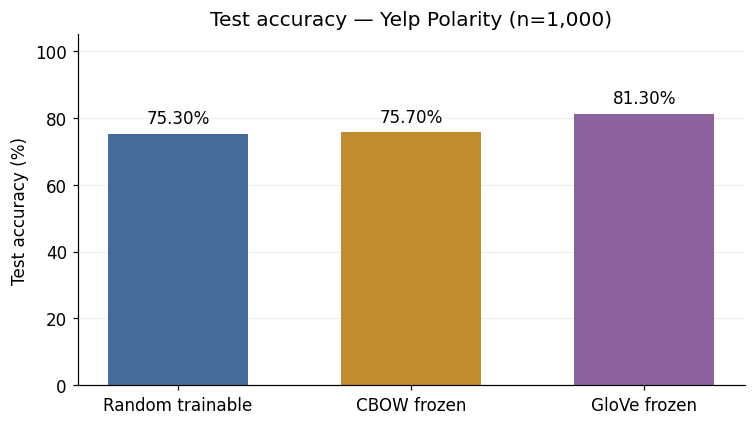

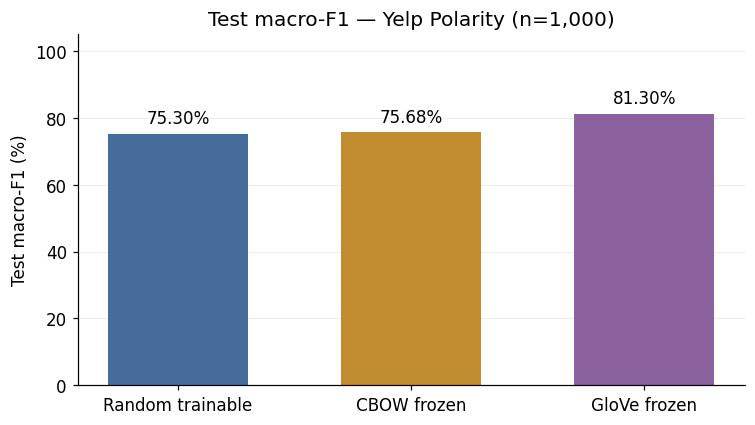

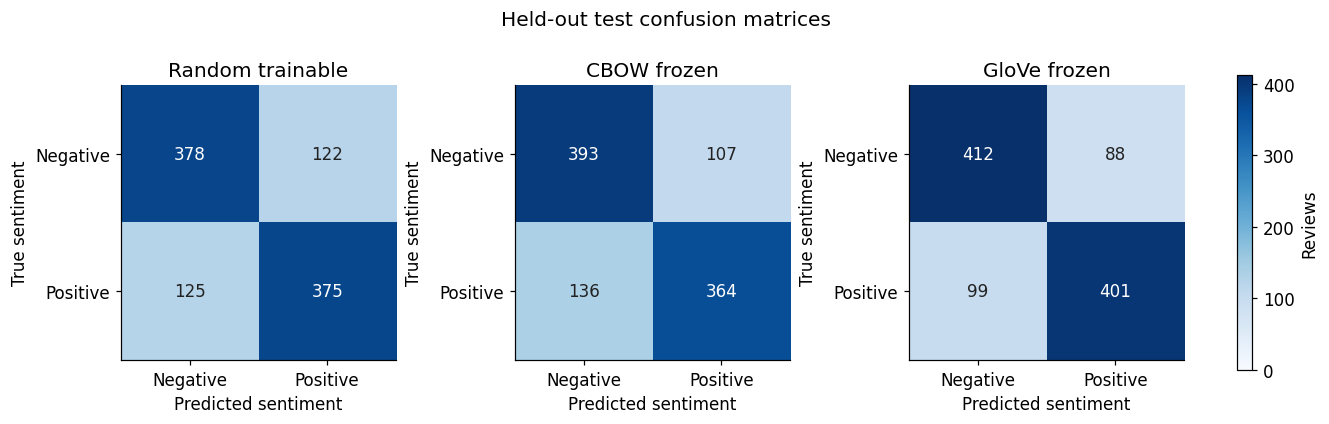

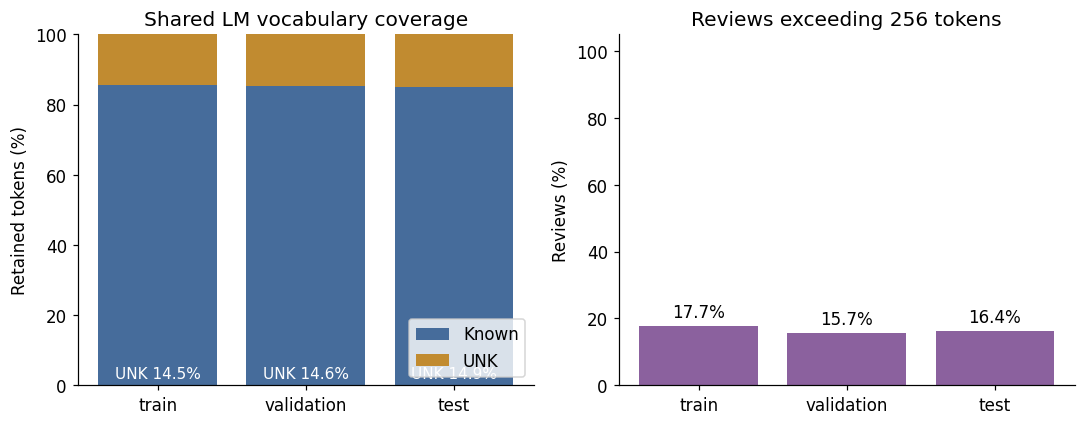

In [13]:
def save_figure(fig,name):
    fig.savefig(FIG_DIR/f'{name}.png',dpi=300,bbox_inches='tight')
    fig.savefig(FIG_DIR/f'{name}.pdf',bbox_inches='tight')
    plt.show(); plt.close(fig)

for metric,title in [('test_accuracy','Test accuracy'),('test_macro_f1','Test macro-F1')]:
    fig,ax=plt.subplots(figsize=(7,4))
    vals=results.set_index('variant').loc[VARIANTS,metric].to_numpy()*100
    bars=ax.bar([DISPLAY_NAMES[v] for v in VARIANTS],vals,color=[COLORS[v] for v in VARIANTS],width=.6)
    ax.set(ylim=(0,105),ylabel=title+' (%)',title=f'{title} — Yelp Polarity (n={SAMPLE_COUNTS["test"]:,})')
    ax.set_yticks([0,20,40,60,80,100]); ax.grid(axis='y',alpha=.2); ax.set_axisbelow(True)
    ax.bar_label(bars,labels=[f'{v:.2f}%' for v in vals],padding=4)
    fig.tight_layout(); save_figure(fig,metric)

fig,axes=plt.subplots(1,3,figsize=(12,3.8),layout='constrained')
maximum=max(np.array(cm).max() for cm in confusion.values())
for ax,variant in zip(axes,VARIANTS):
    cm=np.array(confusion[variant]); im=ax.imshow(cm,cmap='Blues',vmin=0,vmax=maximum)
    ax.set(xticks=[0,1],yticks=[0,1],xticklabels=LABEL_NAMES,yticklabels=LABEL_NAMES,
           xlabel='Predicted sentiment',ylabel='True sentiment',title=DISPLAY_NAMES[variant])
    for i in range(2):
        for j in range(2): ax.text(j,i,str(cm[i,j]),ha='center',va='center',color='white' if cm[i,j]>maximum/2 else '#222222')
fig.colorbar(im,ax=axes,shrink=.8,label='Reviews')
fig.suptitle('Held-out test confusion matrices'); save_figure(fig,'confusion_matrices')

fig,axes=plt.subplots(1,2,figsize=(10,4))
cv=coverage.set_index('split').loc[list(SAMPLE_COUNTS)]
axes[0].bar(cv.index,100*cv.known_token_coverage,label='Known',color='#466C9B')
axes[0].bar(cv.index,100*cv.unknown_token_rate,bottom=100*cv.known_token_coverage,label='UNK',color='#C18B30')
axes[0].set(ylim=(0,100),ylabel='Retained tokens (%)',title='Shared LM vocabulary coverage'); axes[0].legend(loc='lower right')
for i,value in enumerate(cv.unknown_token_rate): axes[0].text(i,2,f'UNK {100*value:.1f}%',ha='center',color='white',fontsize=10)
bars=axes[1].bar(cv.index,100*cv.truncation_rate,color='#8B619E')
axes[1].set(ylim=(0,105),ylabel='Reviews (%)',title=f'Reviews exceeding {MAX_REVIEW_TOKENS} tokens')
axes[1].bar_label(bars,labels=[f'{100*v:.1f}%' for v in cv.truncation_rate],padding=3)
fig.tight_layout(); save_figure(fig,'coverage_and_truncation')

## 11. Disagreements and representative errors

In [14]:
test=df[df.split=='test'].copy().reset_index(drop=True)
for variant in VARIANTS:
    p=predictions[(predictions.variant==variant)&(predictions.split=='test')].set_index('review_id')
    assert set(p.index)==set(test.review_id)
    test[f'pred_{variant}']=test.review_id.map(p.prediction).astype(int)
    test[f'p_positive_{variant}']=test.review_id.map(p.prob_positive)
    test[f'correct_{variant}']=test[f'pred_{variant}']==test.label
correct=test[[f'correct_{v}' for v in VARIANTS]].to_numpy()
test['correct_count']=correct.sum(axis=1)
test['unk_rate']=test.unknown_count/test.retained_token_count
train_unk=np.array([r['unknown_count']/r['retained_token_count'] for r in SPLIT_ROWS['train']])
UNK_CUTOFF=max(.10,float(np.quantile(train_unk,.75)))
def has_negation(tokens):
    return any(t in {'not','no','never','neither','nor','without','hardly'} or t.endswith("n't") for t in tokens)
test['negation_candidate']=test.tokens.map(has_negation)
test['contrast_candidate']=test.tokens.map(lambda ts:bool(set(ts)&{'but','however','although','yet'}))
test['high_unk_candidate']=(test.unk_rate>=UNK_CUTOFF)&(test.unknown_count>0)
categories={
    'Correct by all three':test.correct_count==3,
    'Wrong by all three':test.correct_count==0,
    'GloVe correct; CBOW or random wrong':test.correct_glove_frozen & (~test.correct_cbow_frozen | ~test.correct_random_trainable),
    'CBOW correct; GloVe wrong':test.correct_cbow_frozen & ~test.correct_glove_frozen,
    'Negation candidates with at least one error':test.negation_candidate & (test.correct_count<3),
    'Possible mixed sentiment / contrast with an error':test.contrast_candidate & (test.correct_count<3),
    'Unfamiliar vocabulary candidates with an error':test.high_unk_candidate & (test.correct_count<3),
}
category_counts=pd.DataFrame([{'category':name,'reviews':int(mask.sum())} for name,mask in categories.items()])
category_counts.to_csv(RUN_DIR/'error_category_counts.csv',index=False)
display(category_counts)
pairwise=[]
for i,a in enumerate(VARIANTS):
    for b in VARIANTS[i+1:]:
        a_ok=test[f'correct_{a}']; b_ok=test[f'correct_{b}']
        pairwise.append({'variant_a':a,'variant_b':b,'test_reviews':len(test),
            'disagreements':int((test[f'pred_{a}']!=test[f'pred_{b}']).sum()),
            'disagreement_rate':float((test[f'pred_{a}']!=test[f'pred_{b}']).mean()),
            'a_correct_b_wrong':int((a_ok&~b_ok).sum()),'b_correct_a_wrong':int((b_ok&~a_ok).sum()),
            'both_correct':int((a_ok&b_ok).sum()),'both_wrong':int((~a_ok&~b_ok).sum())})
pd.DataFrame(pairwise).to_csv(RUN_DIR/'pairwise_disagreements.csv',index=False)
display(pd.DataFrame(pairwise))
subgroups=[]
for group,mask in {'all':np.ones(len(test),dtype=bool),'negation_candidate':test.negation_candidate,
                  'contrast_candidate':test.contrast_candidate,'high_unk_candidate':test.high_unk_candidate,
                  'truncated':test.truncated,'not_truncated':~test.truncated}.items():
    for variant in VARIANTS:
        subgroups.append({'group':group,'variant':variant,'reviews':int(np.sum(mask)),
            'error_rate':float((~test.loc[mask,f'correct_{variant}']).mean()) if np.any(mask) else None})
pd.DataFrame(subgroups).to_csv(RUN_DIR/'error_subgroups.csv',index=False)
write_json(RUN_DIR/'error_analysis_rules.json',{'seed':SEED+10,'examples_per_category':EXAMPLES_PER_CATEGORY,
    'high_unk_cutoff':UNK_CUTOFF,'candidate_flags_are_heuristics':True,'categories_overlap':True})
selected_examples=[]; html_blocks=[]
for name,mask in categories.items():
    candidates=test.loc[mask]
    html_blocks.append(f'<h3>{escape(name)} ({len(candidates)} reviews)</h3>')
    if candidates.empty:
        html_blocks.append('<p>No matching examples in this test subset.</p>'); continue
    selected=candidates.sample(n=min(EXAMPLES_PER_CATEGORY,len(candidates)),random_state=SEED+10)
    for _,r in selected.iterrows():
        pred_text=' | '.join(f'{DISPLAY_NAMES[v]}: {LABEL_NAMES[int(r[f"pred_{v}"])]}, P(positive)={r[f"p_positive_{v}"]:.3f}' for v in VARIANTS)
        html_blocks.append(f'<p><b>{escape(r.review_id)}</b> · True: {LABEL_NAMES[int(r.label)]} · Truncated: {r.truncated} · UNK: {r.unk_rate:.1%}</p>')
        html_blocks.append('<p>'+escape(pred_text)+'</p><div style="white-space:pre-wrap;border-left:3px solid #ccc;padding-left:12px">'+escape(r.text)+'</div>')
        html_blocks.append('<details><summary>Retained tokenizer tokens and mapped tokens</summary><p>'+escape(' '.join(r.tokens))+'</p><p>'+escape(' '.join(id_to_token[i] for i in r.token_ids))+'</p></details>')
        record={'category':name,'review_id':r.review_id,'text':r.text,'true_label':int(r.label),
                'truncated':bool(r.truncated),'unknown_rate':float(r.unk_rate),'retained_tokens':r.tokens,
                'mapped_tokens':[id_to_token[i] for i in r.token_ids]}
        for v in VARIANTS:
            record[f'prediction_{v}']=int(r[f'pred_{v}']); record[f'prob_positive_{v}']=float(r[f'p_positive_{v}'])
        selected_examples.append(record)
error_html='<!doctype html><meta charset="utf-8"><title>Yelp Part III error examples</title><main style="max-width:1000px;margin:30px auto;font:16px/1.6 sans-serif">'+''.join(html_blocks)+'</main>'
(RUN_DIR/'error_examples.html').write_text(error_html,encoding='utf-8')
write_json(RUN_DIR/'error_examples.json',selected_examples)
test.drop(columns=['tokens','token_ids']).to_csv(RUN_DIR/'test_error_analysis.csv',index=False)
display(HTML(error_html))

,category,reviews
0,Correct by all three,618
1,Wrong by all three,90
2,GloVe correct; CBOW or random wrong,195
3,CBOW correct; GloVe wrong,66
4,Negation candidates with at least one error,275
5,Possible mixed sentiment / contrast with an error,226
6,Unfamiliar vocabulary candidates with an error,128


,variant_a,variant_b,test_reviews,disagreements,disagreement_rate,a_correct_b_wrong,b_correct_a_wrong,both_correct,both_wrong
0,random_trainable,cbow_frozen,1000,184,0.184,90,94,663,153
1,random_trainable,glove_frozen,1000,212,0.212,76,136,677,111
2,cbow_frozen,glove_frozen,1000,188,0.188,66,122,691,121


## 12. Connect language-model quality with downstream quality

,variant,lm_test_ce,lm_test_ppl,test_accuracy,test_macro_f1,lm_ppl_rank,sentiment_macro_f1_rank
0,random_trainable,4.3535,77.7484,0.753,0.7530,1.0,3.0
1,cbow_frozen,4.3602,78.2691,0.757,0.7568,2.0,2.0
2,glove_frozen,4.3690,78.9659,0.813,0.8130,3.0,1.0


,variant_a,variant_b,lower_PPL_vs_higher_macroF1
0,random_trainable,cbow_frozen,disagrees
1,random_trainable,glove_frozen,disagrees
2,cbow_frozen,glove_frozen,disagrees


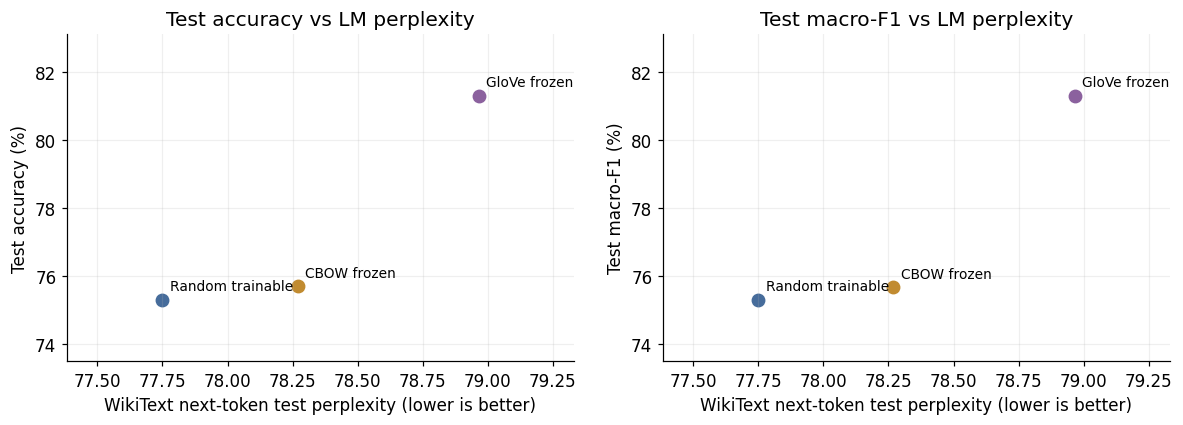

Describe these three variants only. No causal or general statistical claim is supported by this ranking check.


In [15]:
external=[]
if LM_RESULTS_CSV is not None:
    external=pd.read_csv(LM_RESULTS_CSV).to_dict('records')
external+=MANUAL_LM_RESULTS
assert len({r['variant'] for r in external})==len(external), 'Duplicate manually supplied variants.'
external_by_variant={r['variant']:r for r in external}
assert set(external_by_variant).issubset(VARIANTS)
lm_rows=[]; automatic_signatures=[]
for variant,folder in RUN_DIRS.items():
    metric_path=folder/'metrics.json'
    if variant in external_by_variant:
        m=external_by_variant[variant]; provenance='user supplied; verify common LM evaluation setup'
    elif metric_path.exists():
        m=read_json(metric_path); provenance=str(metric_path)
        assert m['data_hash']==MODEL_CONFIGS[variant]['data_manifest_sha256']
        assert m['vocab_hash']==MODEL_INFO[variant]['vocab_sha256']
        automatic_signatures.append((m['data_hash'],m['test_target_sha256'],m['test_token_count']))
    else:
        lm_rows.append({'variant':variant,'lm_test_ce':None,'lm_test_ppl':None,'lm_metric_source':'missing; run Part II evaluation or supply metrics'})
        continue
    assert m['variant']==variant and m['checkpoint_sha256']==MODEL_INFO[variant]['checkpoint_sha256'], 'LM metrics refer to a different checkpoint.'
    ce=float(m['test_ce']); ppl=float(m['test_ppl'])
    assert math.isfinite(ce) and ce>=0 and math.isfinite(ppl) and ppl>=1
    assert math.isclose(math.log(ppl),ce,rel_tol=1e-3,abs_tol=1e-3), 'CE/PPL inconsistent; use unrounded Part II outputs.'
    lm_rows.append({'variant':variant,'lm_test_ce':ce,'lm_test_ppl':ppl,'lm_metric_source':provenance})
assert len(set(automatic_signatures))<=1, 'Part II metrics used different evaluation targets.'
linked=results.merge(pd.DataFrame(lm_rows),on='variant',validate='one_to_one')
linked['lm_ppl_rank']=linked.lm_test_ppl.rank(method='min',ascending=True)
linked['sentiment_accuracy_rank']=linked.test_accuracy.rank(method='min',ascending=False)
linked['sentiment_macro_f1_rank']=linked.test_macro_f1.rank(method='min',ascending=False)
linked.to_csv(RUN_DIR/'lm_downstream_comparison.csv',index=False)
write_json(RUN_DIR/'lm_downstream_comparison.json',json.loads(linked.to_json(orient='records')))
display(linked[['variant','lm_test_ce','lm_test_ppl','test_accuracy','test_macro_f1','lm_ppl_rank','sentiment_macro_f1_rank']].round(4))
valid=linked.dropna(subset=['lm_test_ppl'])
rank_pairs=[]
for i in range(len(valid)):
    for j in range(i+1,len(valid)):
        a,b=valid.iloc[i],valid.iloc[j]
        dp=float(a.lm_test_ppl-b.lm_test_ppl); df1=float(a.test_macro_f1-b.test_macro_f1)
        status='tie in at least one metric' if np.isclose(dp,0,rtol=0,atol=1e-10) or np.isclose(df1,0,rtol=0,atol=1e-10) else ('agrees' if dp*df1<0 else 'disagrees')
        rank_pairs.append({'variant_a':a.variant,'variant_b':b.variant,'lower_PPL_vs_higher_macroF1':status})
if rank_pairs:
    display(pd.DataFrame(rank_pairs)); pd.DataFrame(rank_pairs).to_csv(RUN_DIR/'ranking_agreement.csv',index=False)
if len(valid)>=2:
    fig,axes=plt.subplots(1,2,figsize=(11,4))
    for ax,metric,title in [(axes[0],'test_accuracy','Test accuracy'),(axes[1],'test_macro_f1','Test macro-F1')]:
        for _,r in valid.iterrows():
            ax.scatter(r.lm_test_ppl,100*r[metric],color=COLORS[r.variant],s=65)
            ax.annotate(DISPLAY_NAMES[r.variant],(r.lm_test_ppl,100*r[metric]),xytext=(5,6),textcoords='offset points',fontsize=9)
        ax.margins(.3); ax.set(xlabel='WikiText next-token test perplexity (lower is better)',ylabel=title+' (%)',title=title+' vs LM perplexity')
        ax.grid(alpha=.2)
    fig.tight_layout(); save_figure(fig,'lm_vs_downstream')
print('Describe these three variants only. No causal or general statistical claim is supported by this ranking check.')

## 13. Save the final audit and reproduction guide

In [17]:
readme=f"""# Part III: Yelp sentiment from frozen LSTM representations

Run 09_part3_restaurant_sentiment.ipynb in Colab from top to bottom after Part II 06/07/08.
The task uses mixed-business Yelp Polarity, not restaurant-only data.

1. Run dependency cell; restart if Colab requests it.
2. Mount Drive and set PROJECT_ROOT / RUN_DIRS in Section 2.
3. First run: EXTRACTION_MODE=auto and CLASSIFIER_MODE=auto.
4. Later: reuse_only for both switches loads only compatible caches.
5. Do not change settings after inspecting test results to optimize test scores.

Inputs: each Part II run needs best.pt, config.json, training_summary.json,
lstm_model.py, vocab.json, preprocessing.py, common_data_config.json.
Optional metrics.json supplies next-token CE/PPL; vocabulary_coverage.csv supplies embedding-source coverage.
No CBOW training file, GloVe download, or original raw WikiText files are needed here.

Source: https://huggingface.co/datasets/fancyzhx/yelp_polarity
Pinned revision: {DATA_MANIFEST['source']['revision']}
Labels: 0 negative, 1 positive; official train/test preserved.
Selected counts: {SAMPLE_COUNTS}; seed: {SEED}.
Data cache: {DATA_DIR}
Experiment outputs: {RUN_DIR}
LM block length: {BLOCK_LENGTH}; retained review limit: {MAX_REVIEW_TOKENS} lexical tokens.
Mean pooling: top LSTM layer; PAD/BOS/EOS excluded; UNK included; token-weighted across chunks.
All LMs frozen, eval mode, inference_mode; no LM optimization.
Classifier: training-fitted StandardScaler + L2 logistic regression.
C grid: {C_GRID}; validation macro-F1 selection, accuracy then smaller C tie-break.
Selected candidate remains training-only fitted; threshold 0.5; no train+validation refit.

Use configuration.json, model_artifacts.json, dataset_source.json and split_manifest.csv to audit inputs.
Inspect sessions/*/environment.json and requirements-lock.txt for hardware and dependency versions.
Cached metadata retains original compute times; a cache hit is not reported as zero training cost.
Cache keys include checkpoint, split content/order/labels, tokenizer/vocabulary, and method configuration.
Run output manifest references the compatible cached feature and classifier files.

Limitations: one LM seed and one labeled split; mixed businesses; no business/user grouping;
WikiText-to-Yelp domain shift; truncated reviews; chunk boundaries; mean-pooling information loss;
rating-derived polarity; neutral reviews omitted; possible near-duplicates; pretrained GloVe exposure not audited.
Input settings combine embedding source and trainability, not a pure source-only causal ablation.
Three ranking points do not support a strong correlation or statistical-generalization claim.

Sources: Zhang, Zhao & LeCun (2015), Character-level Convolutional Networks for Text Classification.
Hugging Face dataset card and loading docs: https://huggingface.co/docs/datasets/loading
Logistic regression: https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html
Adapted from the user's Part I/II LSTM and preprocessing notebooks, with coding-assistant help.
Read and explain the implementation and write interpretation in your own words.
"""
(RUN_DIR/'README.md').write_text(readme,encoding='utf-8')
write_json(RUN_DIR/'cache_locations.json',{
    'dataset':str(DATA_DIR),'features':extraction_table[['variant','split','cache_folder','features_sha256']].to_dict('records'),
    'classifiers':{v:CLASSIFIER_META[v]['cache_folder'] for v in VARIANTS}})
output_hashes={str(p.relative_to(RUN_DIR)):sha256(p) for p in sorted(RUN_DIR.rglob('*'))
               if p.is_file() and 'sessions' not in p.relative_to(RUN_DIR).parts and p.name!='output_manifest.json'}
write_json(RUN_DIR/'output_manifest.json',{'configuration_hash':object_hash(RUN_SPEC),'files':output_hashes,
    'all_variants_evaluated':True,'lm_metrics_complete':bool(linked.lm_test_ppl.notna().all()),
    'lm_training_performed':False,'test_used_for_selection':False,'completed_utc':datetime.now(timezone.utc).isoformat()})
print('PART III COMPLETE')
print('Main table:',RUN_DIR/'comparison.csv')
print('Language-model comparison:',RUN_DIR/'lm_downstream_comparison.csv')
print('Error examples:',RUN_DIR/'error_examples.html')
print('Figures:',FIG_DIR)
if linked.lm_test_ppl.isna().any():
    print('ACTION: provide missing Part II LM metrics and rerun Sections 12–14 before writing the cross-task ranking discussion.')

PART III COMPLETE
Main table: /content/drive/MyDrive/DSA4213_Assignment1/partIII/yelp_polarity/runs/75004512bd2b2c41a798/comparison.csv
Language-model comparison: /content/drive/MyDrive/DSA4213_Assignment1/partIII/yelp_polarity/runs/75004512bd2b2c41a798/lm_downstream_comparison.csv
Error examples: /content/drive/MyDrive/DSA4213_Assignment1/partIII/yelp_polarity/runs/75004512bd2b2c41a798/error_examples.html
Figures: /content/drive/MyDrive/DSA4213_Assignment1/partIII/yelp_polarity/runs/75004512bd2b2c41a798/figures
